In [58]:
import pandas as pd
import matplotlib.pyplot as plt

In [59]:
# Function to read time series data from an Excel file
def read_price_time_series(file_path):
    """
    Reads time series data from the 'price' sheet of an Excel file.

    :param file_path: Path to the Excel file
    :return: DataFrame containing the time series data
    """
    try:
        # Read the 'price' sheet
        data = pd.read_excel(file_path, sheet_name="price")
        
        # Optional: Ensure the first column is treated as the index (e.g., Date)
        if data.columns[0].lower() in ['date', 'time', 'datetime']:
            data.set_index(data.columns[0], inplace=True)
        
        print("Data successfully loaded:")
        print(data.head())  # Display the first few rows
        
        return data
    except Exception as e:
        print(f"Error reading file: {e}")
        return None

In [60]:
# Provide the path to your Excel file
file_path = "data-1.xlsx"  # Replace with your actual file path
time_series_data = read_price_time_series(file_path)

Data successfully loaded:
        Data  SUPERCOM (NAS)  NORTHROP GRUMMAN  MANHATTAN ASSOCS.  \
0 2014-01-01         923.999            114.61              29.37   
1 2014-02-01        1199.999            113.25              33.26   
2 2014-03-01        1176.000            121.02              37.24   
3 2014-04-01        1274.000            123.95              35.90   
4 2014-05-01        1548.000            120.61              31.70   

   GEN DIGITAL  ZIX DEAD - DELIST.27/12/21  INTRUSION  \
0      13.6236                        4.56       26.4   
1      11.9886                        4.41       33.0   
2      12.3583                        4.47       44.0   
3      11.6592                        4.18       46.0   
4      11.6477                        3.32       46.0   

   CHECK POINT SFTW.TECHS.  VERISIGN  NETWORK-1 TECHNOLOGIES  \
0                   64.499    59.780                    1.58   
1                   63.430    56.280                    1.65   
2                   67.2

In [61]:
time_series_data.head()

,Data,SUPERCOM (NAS),NORTHROP GRUMMAN,MANHATTAN ASSOCS.,GEN DIGITAL,ZIX DEAD - DELIST.27/12/21,INTRUSION,CHECK POINT SFTW.TECHS.,VERISIGN,NETWORK-1 TECHNOLOGIES,TREND MICRO (OTC)
0,2014-01-01,923.999,114.61,29.37,13.6236,4.56,26.4,64.499,59.780,1.58,35.55
1,2014-02-01,1199.999,113.25,33.26,11.9886,4.41,33.0,63.430,56.280,1.65,31.09
2,2014-03-01,1176.000,121.02,37.24,12.3583,4.47,44.0,67.250,55.190,1.70,32.66
3,2014-04-01,1274.000,123.95,35.90,11.6592,4.18,46.0,68.170,53.950,1.73,31.00
4,2014-05-01,1548.000,120.61,31.70,11.6477,3.32,46.0,64.180,47.605,1.58,31.09


In [62]:
import matplotlib.pyplot as plt

def plot_time_series(data):
    """
    Plots all historical time series in the DataFrame, using the first column as the x-axis (assumed to be dates).
    
    :param data: DataFrame containing the time series data
    """
    try:
        # Assicurarsi che la colonna delle date sia nel formato corretto
        data[data.columns[0]] = pd.to_datetime(data[data.columns[0]])

        # Imposta la colonna delle date come indice per plottare correttamente
        data = data.set_index(data.columns[0])
        
        # Seleziona solo le colonne numeriche
        numeric_data = data.select_dtypes(include='number')
        
        # Plot delle serie temporali
        numeric_data.plot(figsize=(12, 6), legend=True)
        
        # Aggiunta di titolo e etichette
        plt.title('Historical Time Series', fontsize=16)
        plt.xlabel('Date', fontsize=12)  # Etichetta dell'asse x come "Date"
        plt.ylabel('Price', fontsize=12)  # Etichetta dell'asse y come "Price"
        plt.grid(True)
        
        # Mostra la legenda
        plt.legend(title='Series', loc='best')
        
        # Visualizza il grafico
        plt.show()
    except Exception as e:
        print(f"Error creating plot: {e}")


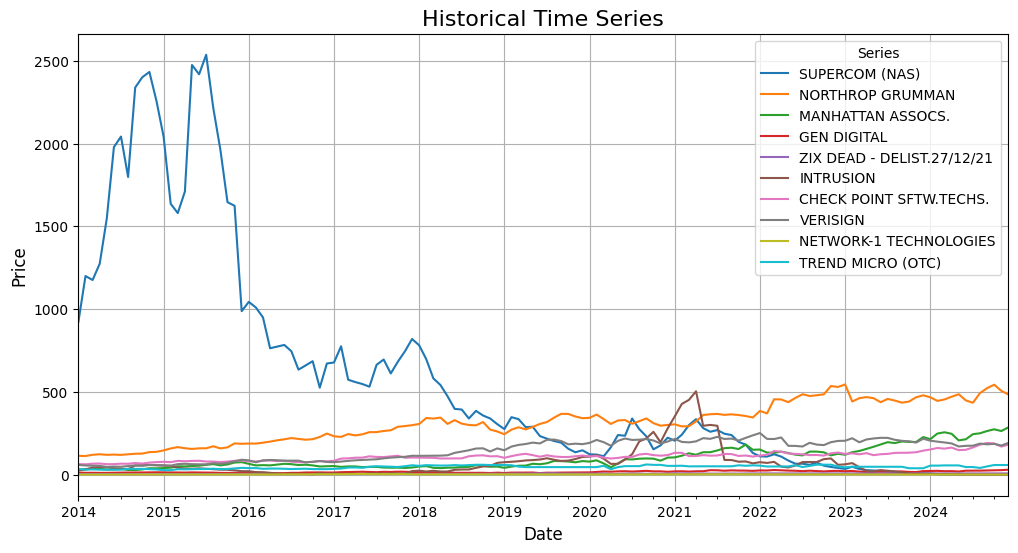

In [63]:
if time_series_data is not None:
    plot_time_series(time_series_data)

In [64]:
def plot_single_series(data):
    """
    Asks the user for a series name and plots the corresponding time series.

    :param data: DataFrame containing the time series data
    """
    try:
        # Display available series names
        print("Available series to plot:")
        print(data.columns[1:].tolist())  # Exclude the first column (date)

        # Ask the user for the series name
        series_name = input("Enter the name of the series you want to plot: ")

        # Check if the series exists in the data
        if series_name not in data.columns[1:]:  # Exclude the first column (date)
            print(f"Series '{series_name}' not found in the dataset.")
            return

        # Plot the selected series
        plt.figure(figsize=(10, 6))
        plt.plot(data[data.columns[0]], data[series_name], label=series_name)

        # Add title and labels
        plt.title(f'{series_name} Time Series', fontsize=16)
        plt.xlabel(data.columns[0], fontsize=12)  # Use the first column name as x-label
        plt.ylabel('Value', fontsize=12)
        plt.grid(True)

        # Show the legend
        plt.legend()
        
        # Show the plot
        plt.show()
    except Exception as e:
        print(f"Error creating plot: {e}")

Available series to plot:
['SUPERCOM (NAS)', 'NORTHROP GRUMMAN', 'MANHATTAN ASSOCS.', 'GEN DIGITAL', 'ZIX DEAD - DELIST.27/12/21', 'INTRUSION', 'CHECK POINT SFTW.TECHS.', 'VERISIGN', 'NETWORK-1 TECHNOLOGIES', 'TREND MICRO (OTC)']
Enter the name of the series you want to plot: VERISIGN


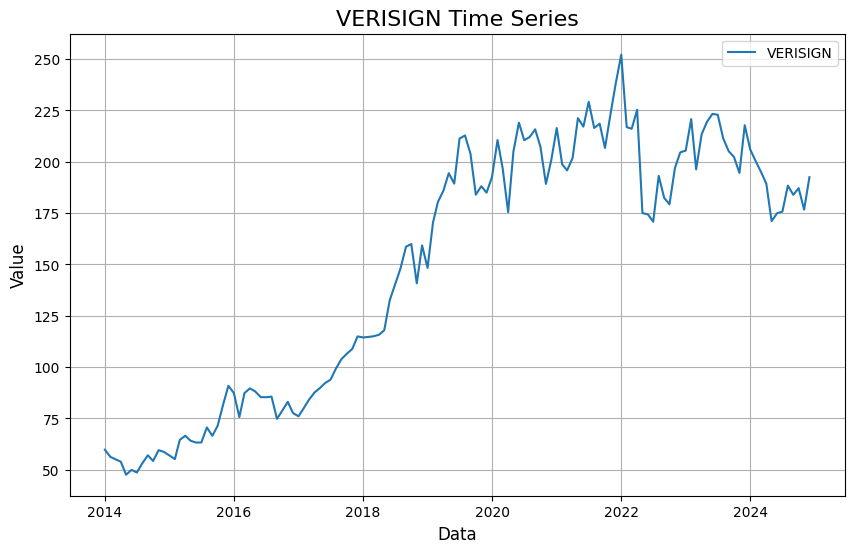

In [66]:
if time_series_data is not None:
    plot_single_series(time_series_data)

In [54]:
# Calcolo dei rendimenti
df_rendimenti = time_series_data.set_index('Data').pct_change().reset_index()

# Aggiunta del prefisso "Rendimento_" ai nomi delle colonne
df_rendimenti.columns = ['Data'] + [f"Yield_{col}" for col in df_rendimenti.columns[1:]]
# Eliminazione delle righe che contengono NaN
df_rendimenti = df_rendimenti.dropna()
# Visualizzazione del nuovo DataFrame
df_rendimenti.head()

,Data,Yield_SUPERCOM (NAS),Yield_NORTHROP GRUMMAN,Yield_MANHATTAN ASSOCS.,Yield_GEN DIGITAL,Yield_ZIX DEAD - DELIST.27/12/21,Yield_INTRUSION,Yield_CHECK POINT SFTW.TECHS.,Yield_VERISIGN,Yield_NETWORK-1 TECHNOLOGIES,Yield_TREND MICRO (OTC)
1,2014-02-01,0.298702,-0.011866,0.132448,-0.120012,-0.032895,0.250000,-0.016574,-0.058548,0.044304,-0.125457
2,2014-03-01,-0.019999,0.068609,0.119663,0.030838,0.013605,0.333333,0.060224,-0.019367,0.030303,0.050499
3,2014-04-01,0.083333,0.024211,-0.035983,-0.056569,-0.064877,0.045455,0.013680,-0.022468,0.017647,-0.050827
4,2014-05-01,0.215071,-0.026946,-0.116992,-0.000986,-0.205742,0.000000,-0.058530,-0.117609,-0.086705,0.002903
5,2014-06-01,0.277777,0.011193,0.029653,0.084326,-0.009036,-0.134783,0.004830,0.049680,0.056962,0.000643


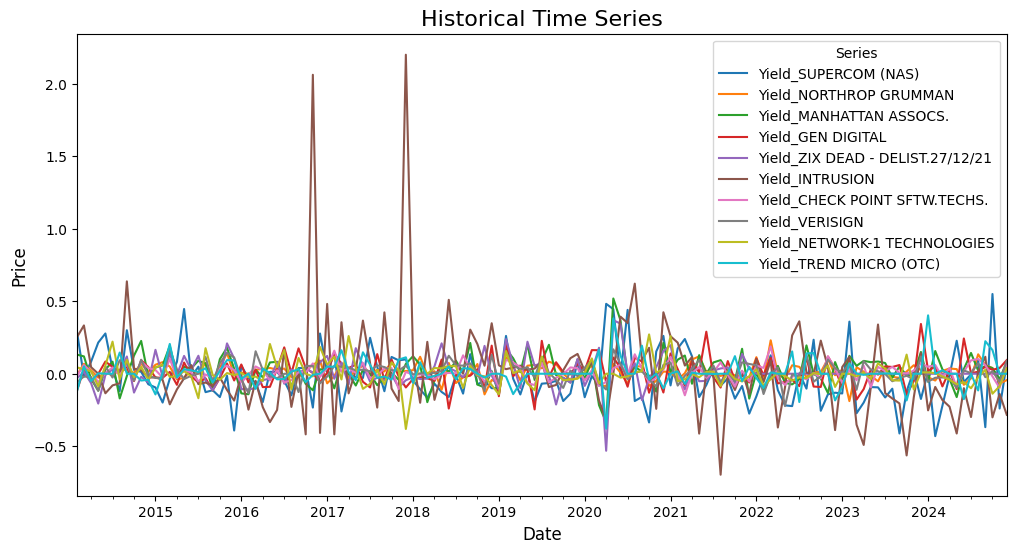

In [55]:
if df_rendimenti is not None:
    plot_time_series(df_rendimenti)

Available series to plot:
['Yield_SUPERCOM (NAS)', 'Yield_NORTHROP GRUMMAN', 'Yield_MANHATTAN ASSOCS.', 'Yield_GEN DIGITAL', 'Yield_ZIX DEAD - DELIST.27/12/21', 'Yield_INTRUSION', 'Yield_CHECK POINT SFTW.TECHS.', 'Yield_VERISIGN', 'Yield_NETWORK-1 TECHNOLOGIES', 'Yield_TREND MICRO (OTC)']
Enter the name of the series you want to plot: Yield_INTRUSION


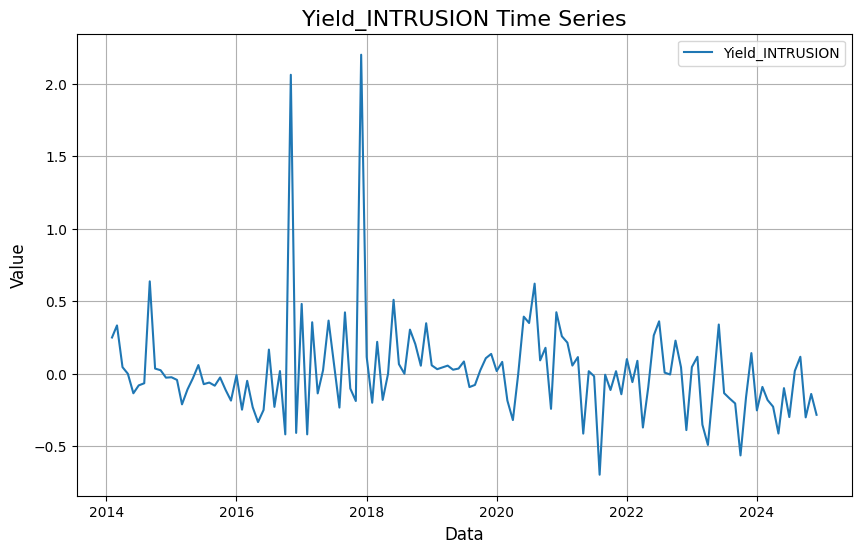

In [45]:
if df_rendimenti is not None:
    plot_single_series(df_rendimenti)